<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/MLEX5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [5]:
df = pd.read_csv("indian_engineering_placement_2026.csv")
print(df.sample(10))
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())

      Student_ID  Age  Gender           State      Branch College_Tier  CGPA  \
8366     ST08367   19  Female          Kerala          IT       Tier-3  7.56   
12134    ST12135   23  Female           Delhi         CSE       Tier-2  7.06   
9528     ST09529   22    Male      Tamil Nadu       Civil       Tier-2  8.25   
258      ST00259   19    Male  Andhra Pradesh         CSE       Tier-2  7.13   
6236     ST06237   21    Male   Uttar Pradesh  Mechanical       Tier-3  8.56   
11636    ST11637   22  Female     Maharashtra         EEE       Tier-3  6.79   
10361    ST10362   21    Male      Tamil Nadu       Civil       Tier-2  8.10   
10139    ST10140   19  Female     West Bengal         CSE       Tier-2  7.68   
3408     ST03409   21    Male          Kerala       Civil       Tier-2  5.79   
11115    ST11116   21    Male       Karnataka    Chemical       Tier-2  8.32   

       Attendance_Percentage  DSA_Problems_Solved  Aptitude_Score  ...  \
8366                   73.56                 

In [6]:
df = pd.read_csv("indian_engineering_placement_2026.csv")
median =df["Open_Source_Contributions"].quantile(0.5)
df["Open_Source_Contributions"]= df["Open_Source_Contributions"].fillna(median)

mean =df["LinkedIn_Activity_Score"].mean()
df["LinkedIn_Activity_Score"]= df["LinkedIn_Activity_Score"].fillna(mean)

print(df.isnull().sum())
df = df.drop_duplicates()

Student_ID                        0
Age                               0
Gender                            0
State                             0
Branch                            0
College_Tier                      0
CGPA                              0
Attendance_Percentage             0
DSA_Problems_Solved               0
Aptitude_Score                    0
Communication_Score               0
Projects_Count                    0
Internships_Count                 0
Certifications_Count              0
Open_Source_Contributions         0
GitHub_Contributions              0
LinkedIn_Activity_Score           0
Hackathons_Participated           0
Competitive_Programming_Rating    0
Study_Hours_Per_Week              0
Soft_Skills_Score                 0
Leadership_Experience             0
Extracurricular_Activities        0
Placement_Status                  0
Package_LPA                       0
dtype: int64


In [7]:
numerical_col = df.select_dtypes(include=['float64','int64'])

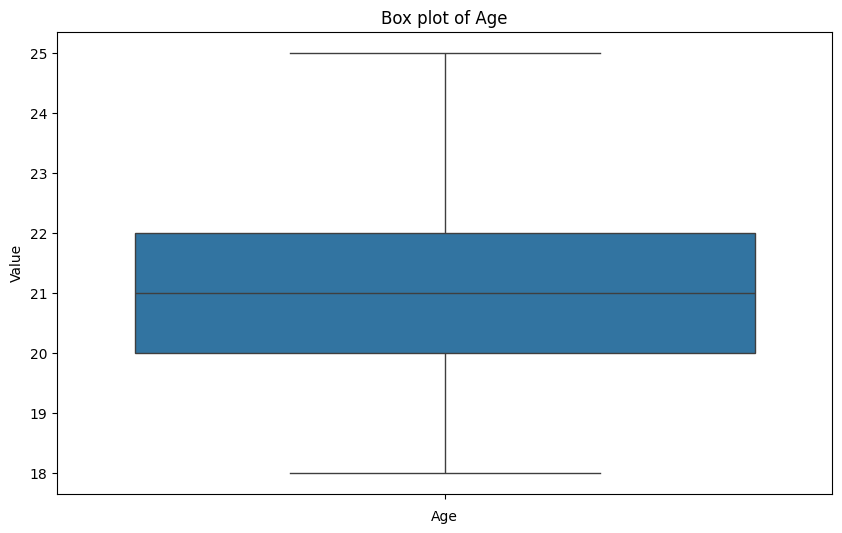

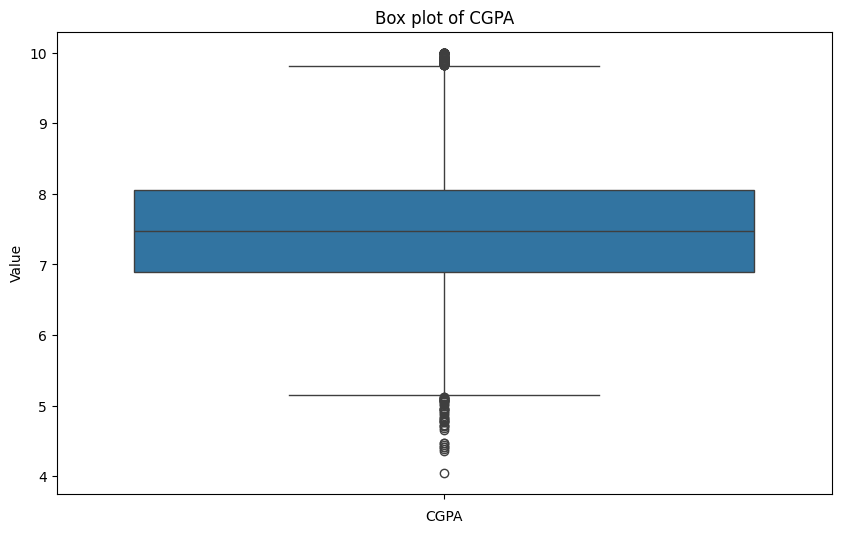

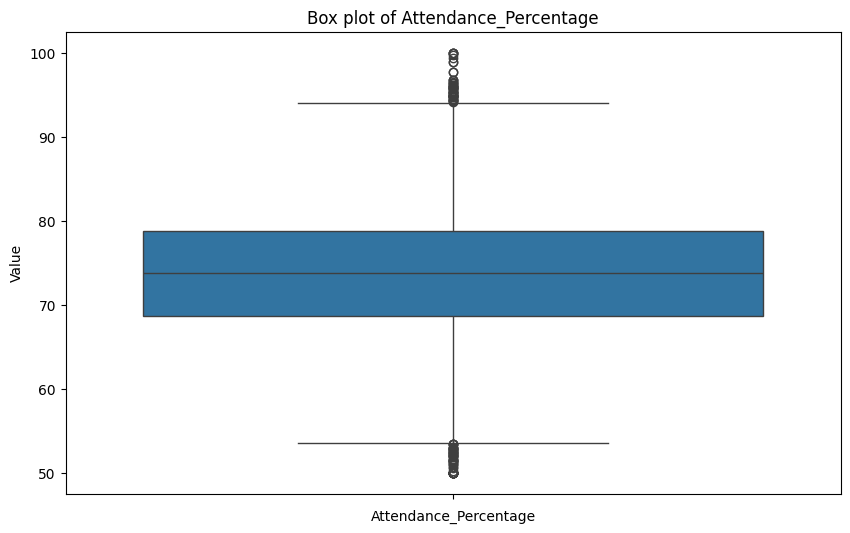

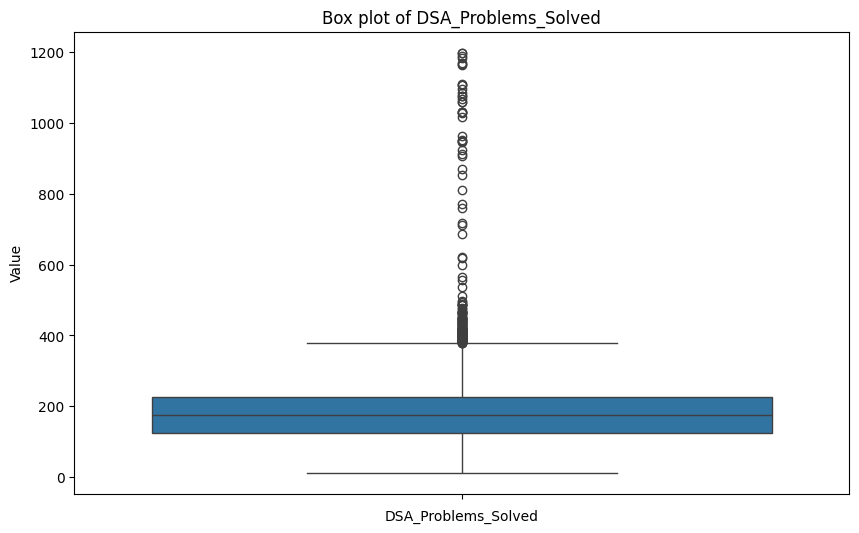

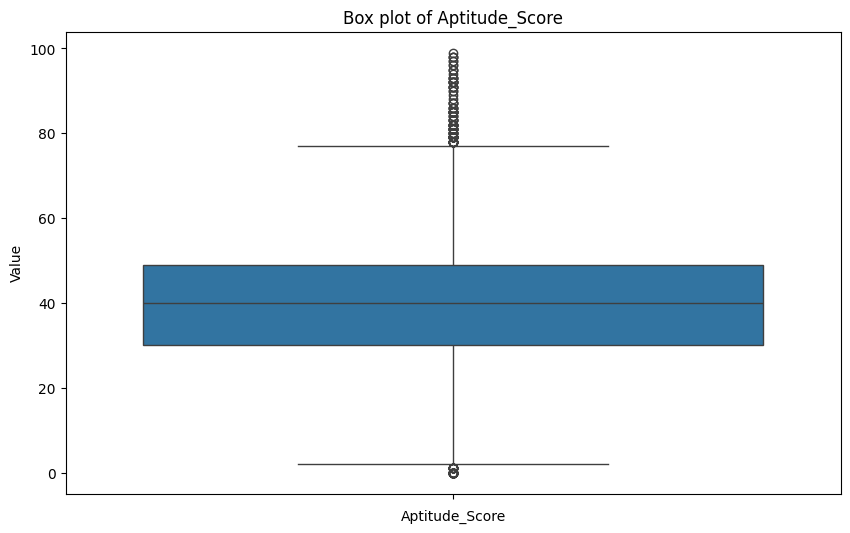

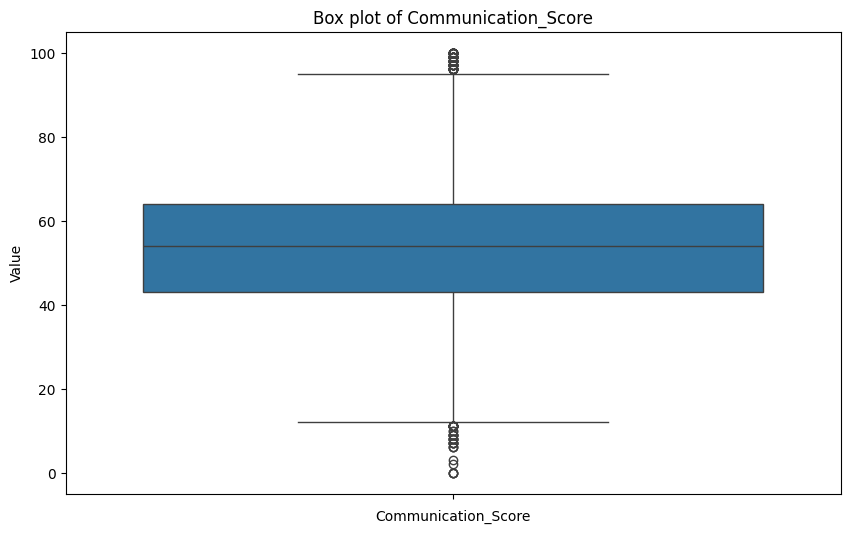

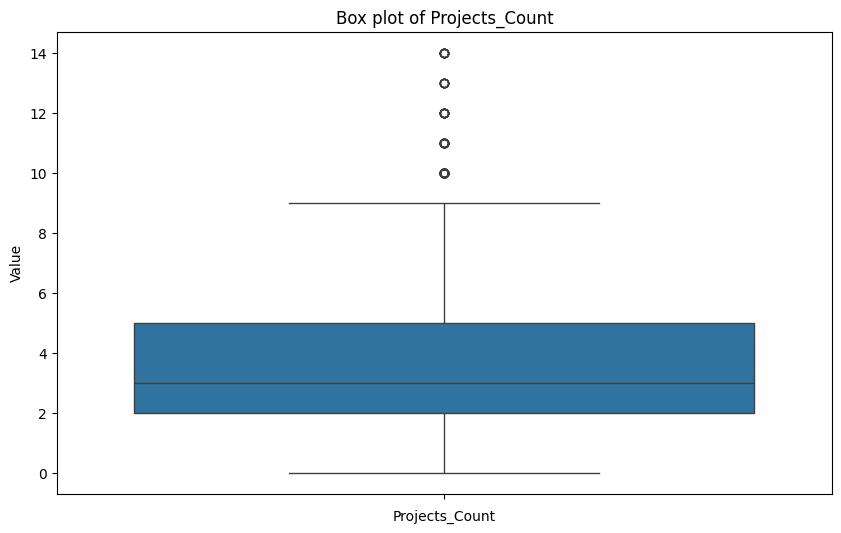

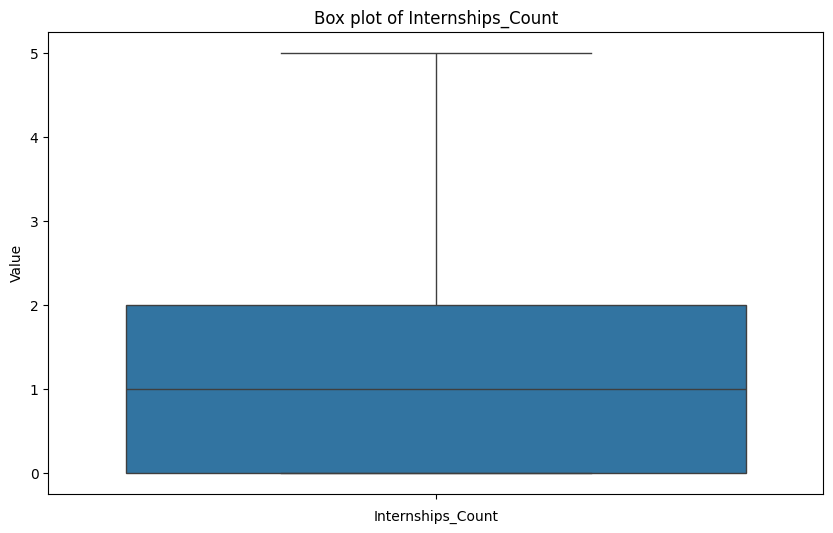

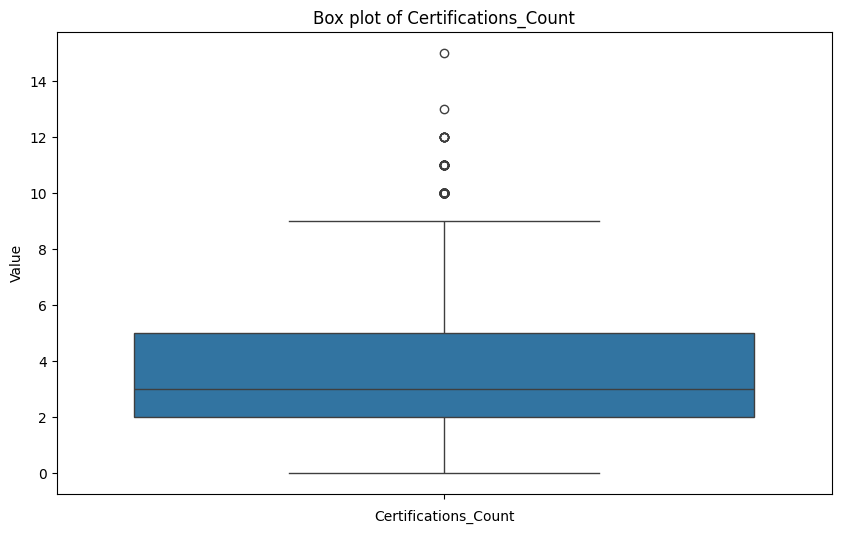

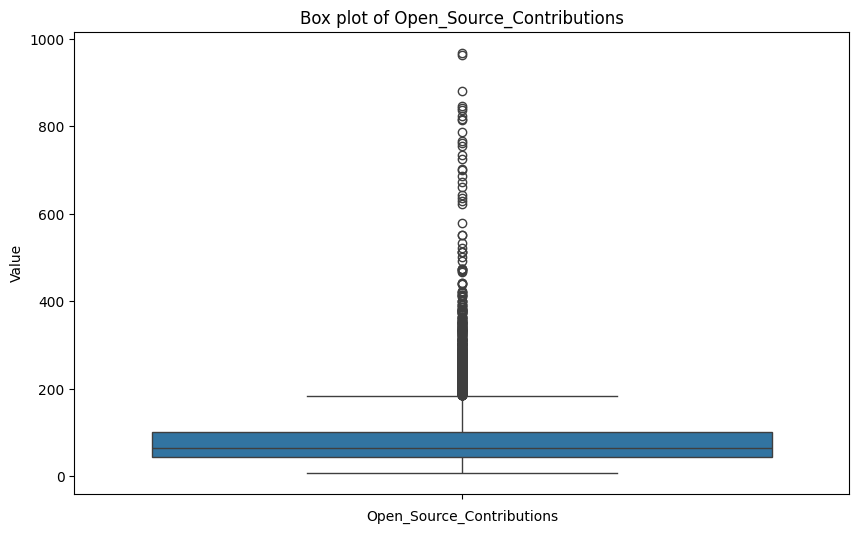

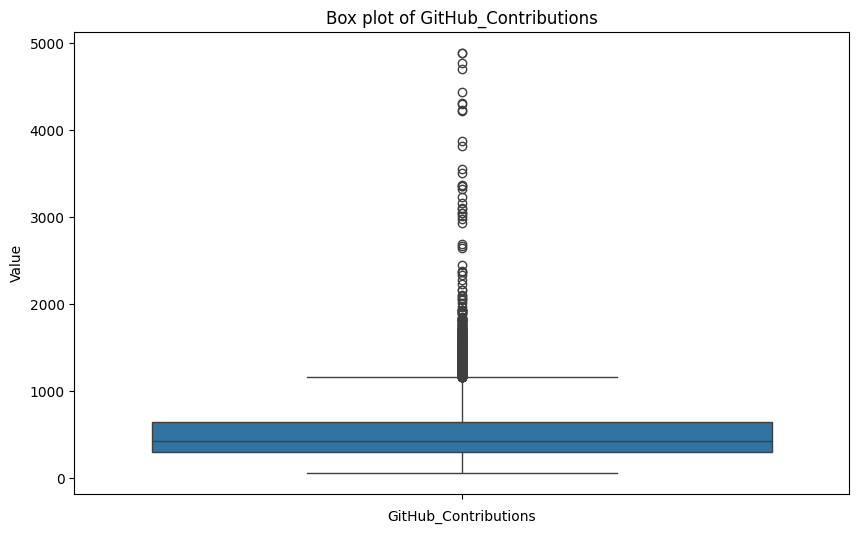

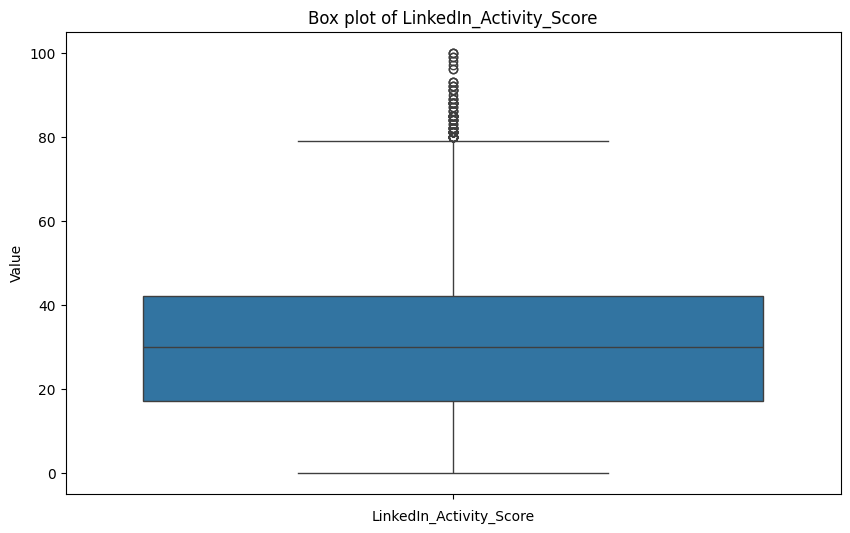

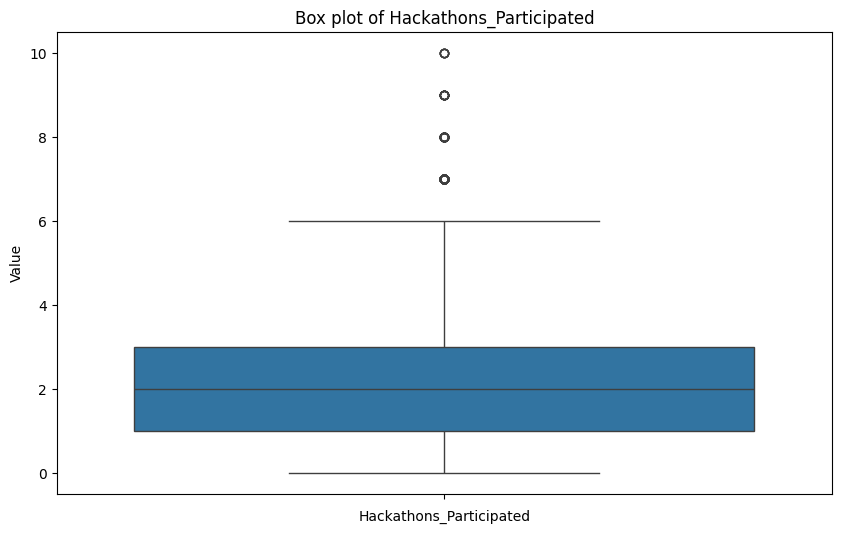

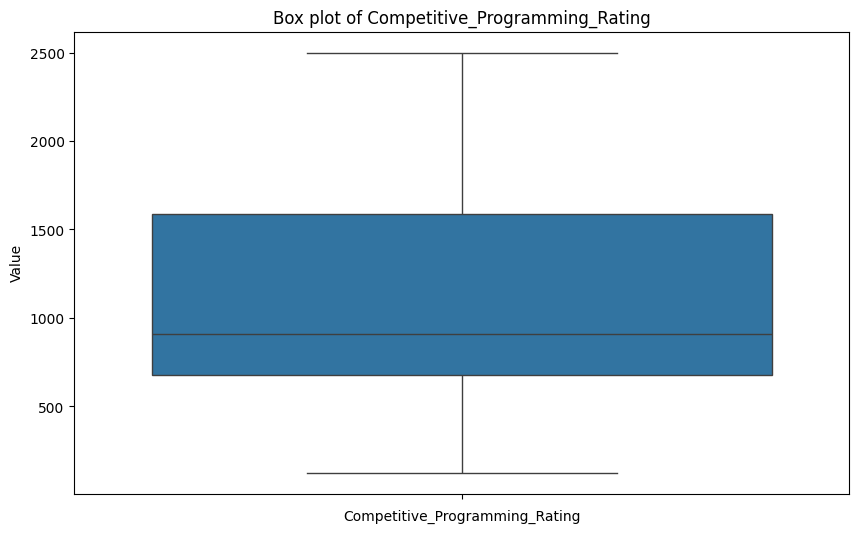

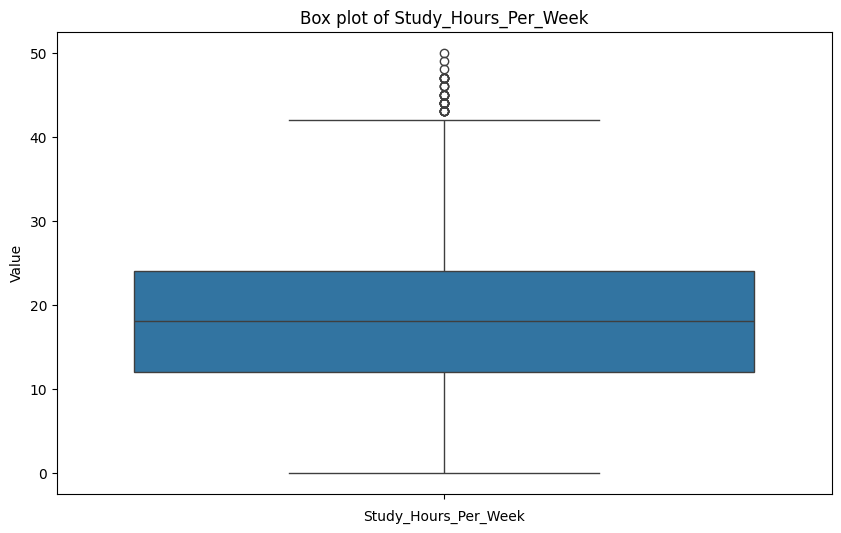

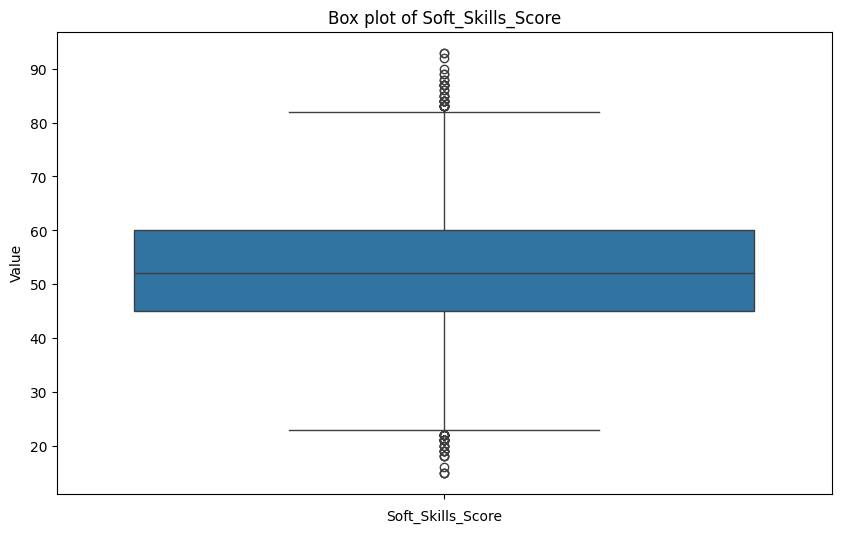

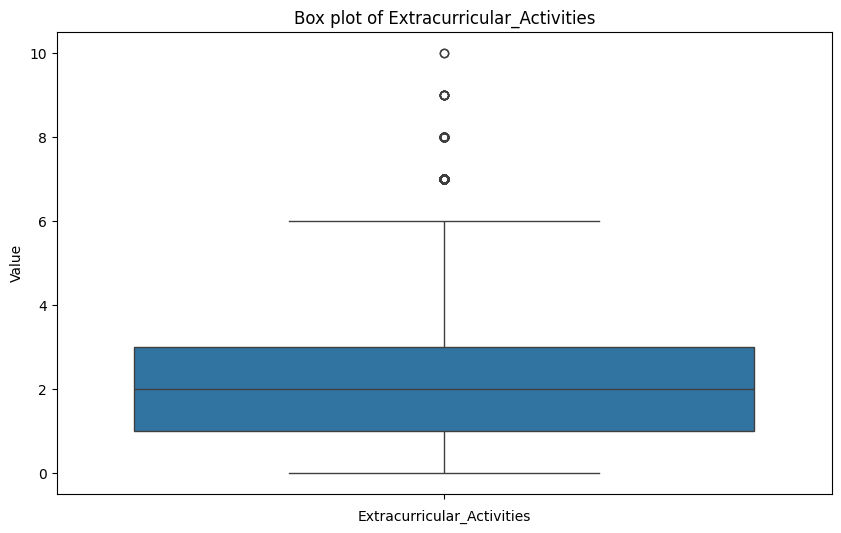

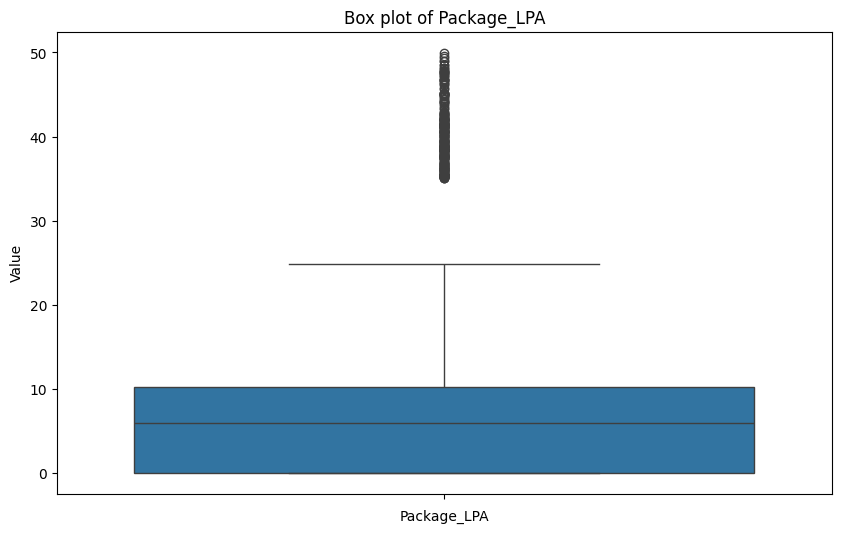

In [8]:
for col in numerical_col:
    plt.figure(figsize=(10, 6))
    sns.boxplot(df[col])
    plt.title(f'Box plot of {col}')
    plt.xlabel(col)
    plt.ylabel('Value')
    plt.show()


In [9]:
#handling outliers
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
#df = df[(df["Age"] >= lower_bound) & (df["Age"] <= upper_bound)]

outliers = df[(df["Age"] < lower_bound) | (df["Age"] > upper_bound)]
print(outliers)

df["Age"] =df["Age"].clip(lower=lower_bound, upper=upper_bound)


Empty DataFrame
Columns: [Student_ID, Age, Gender, State, Branch, College_Tier, CGPA, Attendance_Percentage, DSA_Problems_Solved, Aptitude_Score, Communication_Score, Projects_Count, Internships_Count, Certifications_Count, Open_Source_Contributions, GitHub_Contributions, LinkedIn_Activity_Score, Hackathons_Participated, Competitive_Programming_Rating, Study_Hours_Per_Week, Soft_Skills_Score, Leadership_Experience, Extracurricular_Activities, Placement_Status, Package_LPA]
Index: []

[0 rows x 25 columns]


In [10]:
df = df.drop("Student_ID", axis=1)
df = df.drop("Placement_Status", axis=1)

# Train test split

# Feature Selection and Regression Model

In this section we will:
1. Split the data into training and testing sets.
2. Apply **Variance Threshold** feature selection.
3. Apply **Sequential Feature Selection (SFS)**.
4. Apply **RFE (Recursive Feature Elimination)**.
5. Apply **RFECV (RFE with Cross-Validation)**.
6. Train a simple **Linear Regression** model.
7. Evaluate the model using **R², RMSE, MAE and MSE**.

> **Note:** Since this is a regression problem, we use regression scores such as `r2`, not classification `accuracy`.



In [19]:
from sklearn.model_selection import train_test_split

X = df.drop("Package_LPA", axis=1)
y = df["Package_LPA"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12000, 14)
Testing data: (3000, 14)


In [18]:
# Select only numeric columns
# This keeps the code simple and avoids problems with text/categorical columns.

numeric_data = df.select_dtypes(include=["int64", "float64"]).copy()

X = numeric_data.drop("Package_LPA", axis=1)
y = numeric_data["Package_LPA"]

print("Features:", list(X.columns))
print("Number of features:", X.shape[1])

Features: ['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA', 'Open_Source_Contributions', 'GitHub_Contributions', 'Competitive_Programming_Rating', 'DSA_Problems_Solved']
Number of features: 14


#Apply Feature Selection
## 1. Variance-Based Feature Selection

`VarianceThreshold` removes features whose values do not vary enough.

Here, a threshold of `0.1` is used.


In [20]:
from sklearn.feature_selection import VarianceThreshold

variance_selector = VarianceThreshold(threshold=0.1)

X_train_var = variance_selector.fit_transform(X_train)
X_test_var = variance_selector.transform(X_test)

var_features = X_train.columns[variance_selector.get_support()]

print("Variance Selected Features:")
print(list(var_features))


Variance Selected Features:
['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA', 'Open_Source_Contributions', 'GitHub_Contributions', 'Competitive_Programming_Rating', 'DSA_Problems_Solved']


## Evaluation Function

We will use four regression metrics:

- **R²** → higher is better
- **RMSE** → lower is better
- **MAE** → lower is better
- **MSE** → lower is better


In [22]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

def evaluate_model(X_train_selected, X_test_selected, y_train, y_test):
    model = LinearRegression()
    model.fit(X_train_selected, y_train)

    y_pred = model.predict(X_test_selected)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)

    return r2, rmse, mae, mse


In [23]:
# TRAIN AND EVALUATE ALL FEATURE SELECTION METHODS

results = []

# Variance
r2, rmse, mae, mse = evaluate_model(
    X_train[var_features], X_test[var_features], y_train, y_test
)
results.append(["Variance", r2, rmse, mae, mse])

In [39]:
# Train Linear Regression using Variance Selected Features

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Create the model
model_var = LinearRegression()

# Train the model
model_var.fit(X_train_var, y_train)

# Predict on test data
y_pred_var = model_var.predict(X_test_var)

# Calculate metrics
r2_var = r2_score(y_test, y_pred_var)
mse_var = mean_squared_error(y_test, y_pred_var)
rmse_var = np.sqrt(mse_var)
mae_var = mean_absolute_error(y_test, y_pred_var)

# Print results
print("Variance-Based Feature Selection Model")
print("--------------------------------------")
print("R²   :", round(r2_var, 4))
print("RMSE :", round(rmse_var, 4))
print("MAE  :", round(mae_var, 4))
print("MSE  :", round(mse_var, 4))

Variance-Based Feature Selection Model
--------------------------------------
R²   : 0.5309
RMSE : 4.993
MAE  : 3.5755
MSE  : 24.9304


#Apply Feature Selection
2. Filter Based

## Correlation based


In [12]:
corr = df.corr(numeric_only=True)

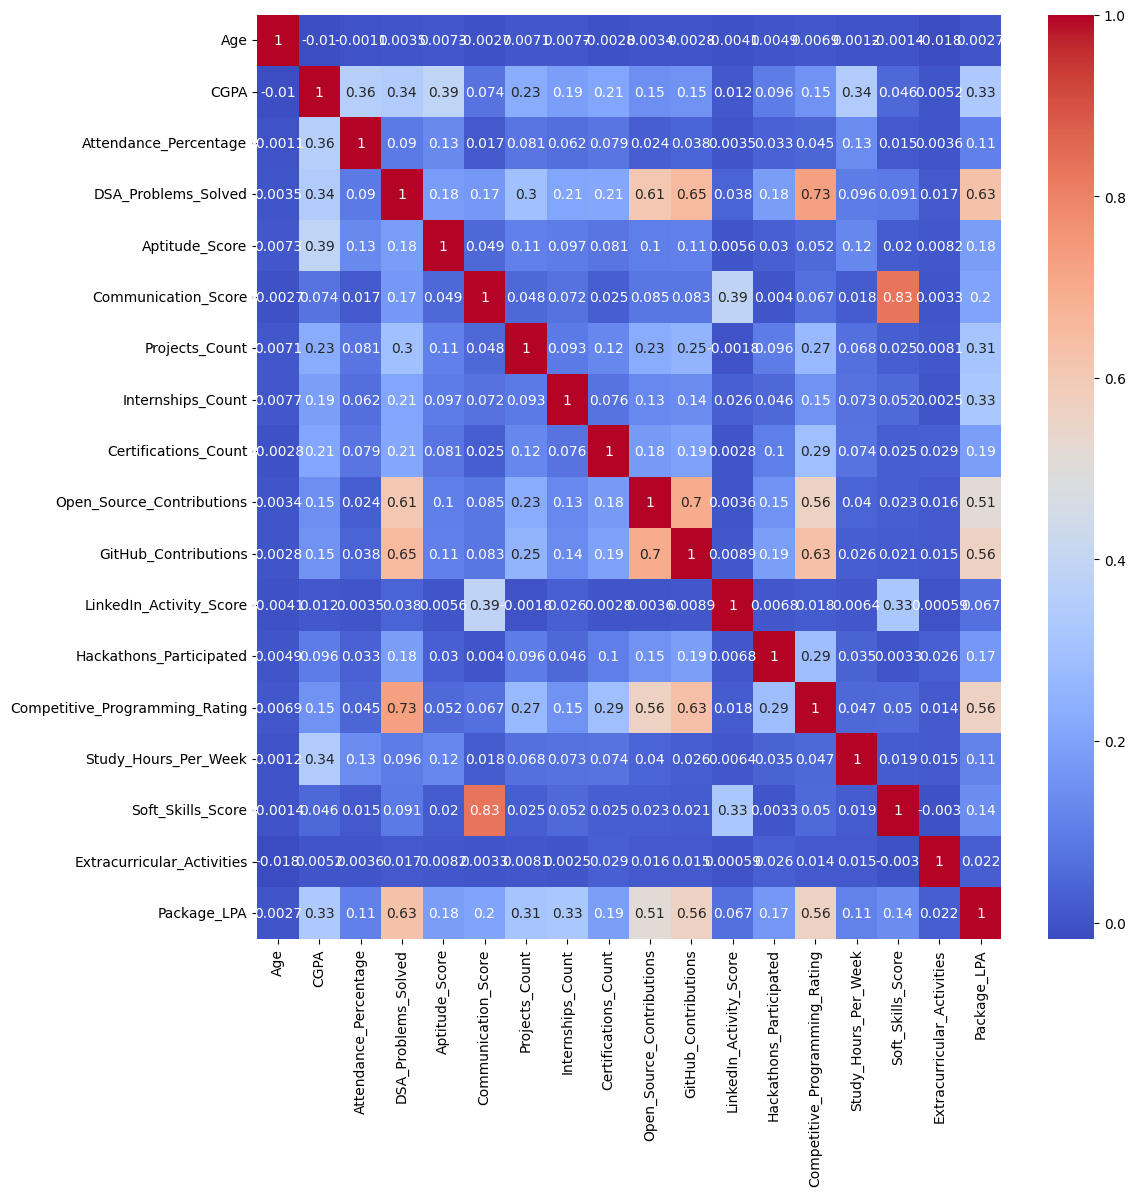

In [13]:
fig = plt.figure(figsize=(12, 12))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

 ## Correlation With Label

In [14]:
correlation = df.corr(numeric_only=True)["Package_LPA"].sort_values(ascending=True)

print(correlation)

Age                               0.002745
Extracurricular_Activities        0.022488
LinkedIn_Activity_Score           0.067193
Attendance_Percentage             0.107772
Study_Hours_Per_Week              0.109882
Soft_Skills_Score                 0.139597
Hackathons_Participated           0.168321
Aptitude_Score                    0.181072
Certifications_Count              0.185551
Communication_Score               0.204367
Projects_Count                    0.309873
Internships_Count                 0.326769
CGPA                              0.330195
Open_Source_Contributions         0.511289
GitHub_Contributions              0.561650
Competitive_Programming_Rating    0.564983
DSA_Problems_Solved               0.627133
Package_LPA                       1.000000
Name: Package_LPA, dtype: float64


In [15]:
# Keep features with |correlation| >= 0.1
selected_features = correlation[correlation.abs() >= 0.1].index

# Create new dataframe
df = df[selected_features]

print(df.columns)

Index(['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score',
       'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count',
       'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'Competitive_Programming_Rating', 'DSA_Problems_Solved', 'Package_LPA'],
      dtype='object')


In [16]:
from sklearn.feature_selection import VarianceThreshold

# Create selector
selector = VarianceThreshold(threshold=0.1)

# Apply to features only
X = df.drop("Package_LPA", axis=1)
y = df["Package_LPA"]

X_selected = selector.fit_transform(X)

# Get selected feature names
selected_features = X.columns[selector.get_support()]

# Create new dataframe
X = pd.DataFrame(X_selected, columns=selected_features, index=df.index)

print("Selected features:")
print(selected_features)

Selected features:
Index(['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score',
       'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count',
       'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA',
       'Open_Source_Contributions', 'GitHub_Contributions',
       'Competitive_Programming_Rating', 'DSA_Problems_Solved'],
      dtype='object')


# Sequential Feature Selection


In [35]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LinearRegression

model = LinearRegression()

# Select up to 5 features, or all features if there are fewer than 5
n_select = min(5, X_train.shape[1])

sfs = SequentialFeatureSelector(
    model,
    n_features_to_select=n_select,
    direction="forward",
    scoring="r2",
    cv=5
)

sfs.fit(X_train, y_train)

sfs_features = X_train.columns[sfs.get_support()]

print("SFS Selected Features:")
print(list(sfs_features))

# Evaluate the SFS model immediately after feature selection
r2_sfs, rmse_sfs, mae_sfs, mse_sfs = evaluate_model(
    X_train[sfs_features], X_test[sfs_features], y_train, y_test
)

print("\n===== SFS Model Metrics =====")
print("R²   :", round(r2_sfs, 4))
print("RMSE :", round(rmse_sfs, 4))
print("MAE  :", round(mae_sfs, 4))
print("MSE  :", round(mse_sfs, 4))

SFS Selected Features:
['Internships_Count', 'CGPA', 'GitHub_Contributions', 'Competitive_Programming_Rating', 'DSA_Problems_Solved']

===== SFS Model Metrics =====
R²   : 0.5129
RMSE : 5.0878
MAE  : 3.6339
MSE  : 25.8861


In [31]:
# Train model using SFS selected features

model_sfs = LinearRegression()
model_sfs.fit(X_train[sfs_features], y_train)

# Prediction
y_pred_sfs = model_sfs.predict(X_test[sfs_features])

# Metrics
r2_sfs = r2_score(y_test, y_pred_sfs)
mse_sfs = mean_squared_error(y_test, y_pred_sfs)
rmse_sfs = np.sqrt(mse_sfs)
mae_sfs = mean_absolute_error(y_test, y_pred_sfs)

print("===== SFS Model =====")
print("R²   :", round(r2_sfs, 4))
print("RMSE :", round(rmse_sfs, 4))
print("MAE  :", round(mae_sfs, 4))
print("MSE  :", round(mse_sfs, 4))

===== SFS Model =====
R²   : 0.5129
RMSE : 5.0878
MAE  : 3.6339
MSE  : 25.8861


# RFE — Recursive Feature Elimination

RFE starts with all features and removes less useful features step-by-step.


In [26]:
from sklearn.feature_selection import RFE

n_rfe = min(5, X_train.shape[1])

rfe = RFE(
    estimator=LinearRegression(),
    n_features_to_select=n_rfe
)

rfe.fit(X_train, y_train)

rfe_features = X_train.columns[rfe.support_]

print("RFE Selected Features:")
print(list(rfe_features))


RFE Selected Features:
['Hackathons_Participated', 'Certifications_Count', 'Projects_Count', 'Internships_Count', 'CGPA']


In [32]:
# Train model using RFE selected features

model_rfe = LinearRegression()
model_rfe.fit(X_train[rfe_features], y_train)

# Prediction
y_pred_rfe = model_rfe.predict(X_test[rfe_features])

# Metrics
r2_rfe = r2_score(y_test, y_pred_rfe)
mse_rfe = mean_squared_error(y_test, y_pred_rfe)
rmse_rfe = np.sqrt(mse_rfe)
mae_rfe = mean_absolute_error(y_test, y_pred_rfe)

print("===== RFE Model =====")
print("R²   :", round(r2_rfe, 4))
print("RMSE :", round(rmse_rfe, 4))
print("MAE  :", round(mae_rfe, 4))
print("MSE  :", round(mse_rfe, 4))

===== RFE Model =====
R²   : 0.2662
RMSE : 6.2446
MAE  : 4.4431
MSE  : 38.9954


### RFECV — RFE with Cross-Validation

RFECV automatically finds a suitable number of features using cross-validation.


In [27]:
from sklearn.feature_selection import RFECV

rfecv = RFECV(
    estimator=LinearRegression(),
    step=1,
    cv=5,
    scoring="r2",
    min_features_to_select=1
)

rfecv.fit(X_train, y_train)

rfecv_features = X_train.columns[rfecv.support_]

print("RFECV Selected Features:")
print(list(rfecv_features))
print("Number of selected features:", len(rfecv_features))


RFECV Selected Features:
['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA', 'Open_Source_Contributions', 'GitHub_Contributions', 'Competitive_Programming_Rating', 'DSA_Problems_Solved']
Number of selected features: 14


In [33]:
# Train model using RFECV selected features

model_rfecv = LinearRegression()
model_rfecv.fit(X_train[rfecv_features], y_train)

# Prediction
y_pred_rfecv = model_rfecv.predict(X_test[rfecv_features])

# Metrics
r2_rfecv = r2_score(y_test, y_pred_rfecv)
mse_rfecv = mean_squared_error(y_test, y_pred_rfecv)
rmse_rfecv = np.sqrt(mse_rfecv)
mae_rfecv = mean_absolute_error(y_test, y_pred_rfecv)

print("===== RFECV Model =====")
print("R²   :", round(r2_rfecv, 4))
print("RMSE :", round(rmse_rfecv, 4))
print("MAE  :", round(mae_rfecv, 4))
print("MSE  :", round(mse_rfecv, 4))

===== RFECV Model =====
R²   : 0.5309
RMSE : 4.993
MAE  : 3.5755
MSE  : 24.9304


##  Train and Evaluate All Feature Selection Methods

The same Linear Regression model is trained after each feature-selection method.


In [41]:
results = []

# Variance
r2, rmse, mae, mse = evaluate_model(
    X_train[var_features], X_test[var_features], y_train, y_test
)
results.append(["Variance", r2, rmse, mae, mse])

# SFS
r2, rmse, mae, mse = evaluate_model(
    X_train[sfs_features], X_test[sfs_features], y_train, y_test
)
results.append(["SFS", r2, rmse, mae, mse])

# RFE
r2, rmse, mae, mse = evaluate_model(
    X_train[rfe_features], X_test[rfe_features], y_train, y_test
)
results.append(["RFE", r2, rmse, mae, mse])

# RFECV
r2, rmse, mae, mse = evaluate_model(
    X_train[rfecv_features], X_test[rfecv_features], y_train, y_test
)
results.append(["RFECV", r2, rmse, mae, mse])

results_df = pd.DataFrame(
    results,
    columns=["Method", "R2", "RMSE", "MAE", "MSE"]
)

results_df


,Method,R2,RMSE,MAE,MSE
0,Variance,0.530851,4.993032,3.575522,24.930366
1,SFS,0.512866,5.087842,3.633885,25.886133
2,RFE,0.266170,6.244632,4.443125,38.995424
3,RFECV,0.530851,4.993032,3.575522,24.930366


##  Final Model using RFECV Features

RFECV selected features are used for the final simple Linear Regression model.


In [29]:
final_model = LinearRegression()

final_model.fit(X_train[rfecv_features], y_train)

y_pred = final_model.predict(X_test[rfecv_features])

print("Final Selected Features:")
print(list(rfecv_features))

print("\nFinal Model Metrics")
print("R²   :", round(r2_score(y_test, y_pred), 4))
print("RMSE :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("MAE  :", round(mean_absolute_error(y_test, y_pred), 4))
print("MSE  :", round(mean_squared_error(y_test, y_pred), 4))


Final Selected Features:
['Attendance_Percentage', 'Study_Hours_Per_Week', 'Soft_Skills_Score', 'Hackathons_Participated', 'Aptitude_Score', 'Certifications_Count', 'Communication_Score', 'Projects_Count', 'Internships_Count', 'CGPA', 'Open_Source_Contributions', 'GitHub_Contributions', 'Competitive_Programming_Rating', 'DSA_Problems_Solved']

Final Model Metrics
R²   : 0.5309
RMSE : 4.993
MAE  : 3.5755
MSE  : 24.9304


##  Actual vs Predicted Values

The graph compares the actual package values with the values predicted by the final model.


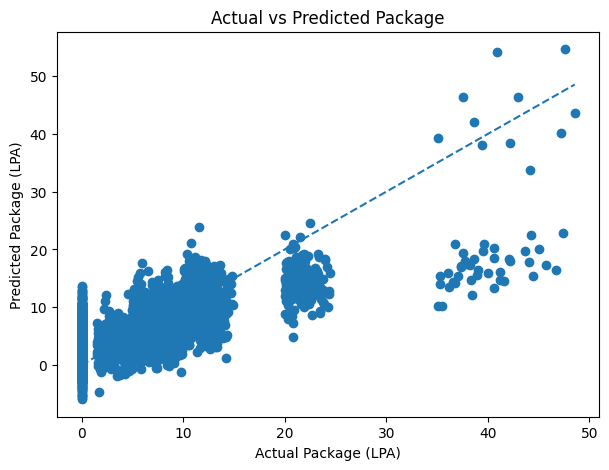

In [30]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Package (LPA)")
plt.ylabel("Predicted Package (LPA)")
plt.title("Actual vs Predicted Package")

# Reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()


## Conclusion

Feature selection helps remove less useful features before training the regression model.

The model is evaluated using **R², RMSE, MAE and MSE**.  
The final Linear Regression model uses the features selected by **RFECV**.


```text
Dataset
   ↓
Train-Test Split
   ↓
 ┌────────────┬────────────┬────────────┬────────────┐
 ↓            ↓            ↓            ↓
Variance      SFS          RFE         RFECV
 ↓            ↓            ↓            ↓
Linear       Linear       Linear       Linear
Regression   Regression   Regression   Regression
 ↓            ↓            ↓            ↓
R² RMSE      R² RMSE      R² RMSE      R² RMSE
MAE MSE      MAE MSE      MAE MSE      MAE MSE
```

```text
R² → HIGH is good
RMSE → LOW is good
MAE → LOW is good
MSE → LOW is good
```

## 🧠 Feature Selection Methods

| Method | Easy Way to Remember | What It Does |
|:---:|:---|:---|
|**Variance** | 📉 Remove low variation | Removes features with very low variance |
| **SFS** | ➕ Add features | Adds useful features step-by-step |
| **RFE** | ❌ Remove features | Removes less important features |
| **RFECV** | 🔄 RFE + CV | RFE + Cross-Validation automatically chooses features |